In [1]:
# Step 1: Install required libraries

!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
# Step 2: Import libraries

import re
import math
import ipaddress
from collections import Counter
from urllib.parse import urlparse

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Environment ready!")

Environment ready!


In [3]:
# Step 3: Extract features from a URL

SUSPICIOUS_TERMS = [
    "login", "verify", "update", "secure",
    "account", "password", "confirm", "signin",
    "wallet", "credential"
]

def extract_features(raw_url):
    url = str(raw_url).strip()

    # Parse URL without visiting it
    parsed = urlparse(
        url if "://" in url else "//" + url
    )

    hostname = parsed.hostname or ""
    lower_url = url.lower()

    try:
        ipaddress.ip_address(hostname)
        has_ip = 1
    except ValueError:
        has_ip = 0

    labels = [x for x in hostname.split(".") if x]

    char_counts = Counter(url)
    total_chars = max(len(url), 1)

    entropy = -sum(
        (count / total_chars) *
        math.log2(count / total_chars)
        for count in char_counts.values()
    )

    return {
        "url_length": len(url),
        "hostname_length": len(hostname),
        "has_ip": has_ip,
        "has_at": int("@" in url),
        "dot_count": url.count("."),
        "hyphen_count": url.count("-"),
        "subdomain_count": max(len(labels) - 2, 0),
        "https_scheme": int(parsed.scheme.lower() == "https"),
        "digit_ratio": sum(c.isdigit() for c in url) / total_chars,
        "entropy": entropy,
        "suspicious_terms": sum(
            term in lower_url for term in SUSPICIOUS_TERMS
        )
    }

# Test feature extraction using a reserved example domain
example = extract_features("https://example.com/login")
print(example)

{'url_length': 25, 'hostname_length': 11, 'has_ip': 0, 'has_at': 0, 'dot_count': 1, 'hyphen_count': 0, 'subdomain_count': 0, 'https_scheme': 1, 'digit_ratio': 0.0, 'entropy': 3.973660689688186, 'suspicious_terms': 1}


In [4]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
import math
from urllib.parse import urlparse

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

# Fetch official UCI dataset
phiusiil = fetch_ucirepo(id=967)

# Combine its feature columns and target column
df_uci = pd.concat(
    [phiusiil.data.features, phiusiil.data.targets],
    axis=1
)

print("UCI shape:", df_uci.shape)
print("\nUCI columns:")
print(df_uci.columns.tolist())

print("\nFirst 5 rows:")
display(df_uci.head())

print("\nUCI label distribution:")
print(df_uci["label"].value_counts() if "label" in df_uci.columns
      else df_uci["Label"].value_counts())

UCI shape: (235795, 55)

UCI columns:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

First 5 rows:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1



UCI label distribution:
label
1    134850
0    100945
Name: count, dtype: int64


In [12]:
print("Label values:", sorted(df["Label"].unique()))

for label in sorted(df["Label"].unique()):
    print(f"\nLabel {label} examples:")
    display(df.loc[df["Label"] == label, ["URL", "Label"]].head(5))

Label values: [np.int64(0), np.int64(1)]

Label 0 examples:


,URL,Label
0,http://electrocoatingmovilparticulares.mobi/w3...,0
2,http://wonoplata.org.ru/olb/5kmxq5zu/mrandapay...,0
6,https://vicky2817.github.io/facebook_login_pag...,0
7,http://uwfaijjxqi.duckdns.org,0
8,https://agrohandler.pl/base,0



Label 1 examples:


,URL,Label
1,https://www.clonefluence.com,1
3,https://www.snohd.org,1
4,https://www.revelrypartyco.com,1
5,https://www.irlspecies.org,1
9,https://www.health.state.mn.us,1


In [13]:
import re
import math
import ipaddress
from urllib.parse import urlparse

def extract_features(url):
    url = str(url).strip()

    # Add scheme if missing, so URL parsing works consistently
    parsed = urlparse(url if "://" in url else "http://" + url)
    hostname = parsed.hostname or ""
    path = parsed.path or ""

    # Check whether hostname is an IP address
    try:
        ipaddress.ip_address(hostname)
        has_ip = 1
    except ValueError:
        has_ip = 0

    # Count URL characters
    url_length = len(url)
    hostname_length = len(hostname)
    path_length = len(path)

    # Count dots and hyphens
    dot_count = url.count(".")
    hyphen_count = url.count("-")

    # Count subdomains approximately
    subdomain_count = max(0, len(hostname.split(".")) - 2)

    # Check for HTTPS and special characters
    has_https = int(parsed.scheme.lower() == "https")
    has_at_symbol = int("@" in url)
    has_double_slash_in_path = int("//" in path)

    # Count digits and suspicious-looking terms
    digit_count = sum(char.isdigit() for char in url)
    suspicious_words = [
        "login", "verify", "update", "secure",
        "account", "banking", "password", "confirm"
    ]
    suspicious_word_count = sum(
        url.lower().count(word) for word in suspicious_words
    )

    # Calculate URL character entropy
    if url:
        probabilities = [
            url.count(char) / len(url) for char in set(url)
        ]
        entropy = -sum(p * math.log2(p) for p in probabilities)
    else:
        entropy = 0

    return {
        "url_length": url_length,
        "hostname_length": hostname_length,
        "path_length": path_length,
        "dot_count": dot_count,
        "hyphen_count": hyphen_count,
        "subdomain_count": subdomain_count,
        "has_ip": has_ip,
        "has_https": has_https,
        "has_at_symbol": has_at_symbol,
        "has_double_slash_in_path": has_double_slash_in_path,
        "digit_count": digit_count,
        "suspicious_word_count": suspicious_word_count,
        "entropy": entropy
    }

print("Feature extraction function created successfully!")

Feature extraction function created successfully!


In [14]:
sample_url = df["URL"].iloc[0]

print("Sample URL:")
print(sample_url)

print("\nExtracted features:")
display(pd.DataFrame([extract_features(sample_url)]))

Sample URL:
http://electrocoatingmovilparticulares.mobi/w3sfqjjkwthnkpq/app1934ff8/4.php

Extracted features:


,url_length,hostname_length,path_length,dot_count,hyphen_count,subdomain_count,has_ip,has_https,has_at_symbol,has_double_slash_in_path,digit_count,suspicious_word_count,entropy
0,76,36,33,2,0,0,0,0,0,0,7,0,4.678188


In [15]:
# Extract features from every URL
features_df = pd.DataFrame(
    df["URL"].apply(extract_features).tolist()
)

# Keep the original labels
X = features_df
y = df["Label"].astype(int)

print("Feature extraction completed!")
print("Total URLs:", len(X))
print("Total features:", X.shape[1])

print("\nFeature names:")
print(X.columns.tolist())

print("\nFirst 5 rows of extracted features:")
display(X.head())

print("\nTarget labels:")
print(y.value_counts())

Feature extraction completed!
Total URLs: 200000
Total features: 13

Feature names:
['url_length', 'hostname_length', 'path_length', 'dot_count', 'hyphen_count', 'subdomain_count', 'has_ip', 'has_https', 'has_at_symbol', 'has_double_slash_in_path', 'digit_count', 'suspicious_word_count', 'entropy']

First 5 rows of extracted features:


,url_length,hostname_length,path_length,dot_count,hyphen_count,subdomain_count,has_ip,has_https,has_at_symbol,has_double_slash_in_path,digit_count,suspicious_word_count,entropy
0,76,36,33,2,0,0,0,0,0,0,7,0,4.678188
1,28,20,0,2,0,1,0,1,0,0,0,0,3.869331
2,81,16,25,2,0,1,0,0,0,0,10,0,4.816392
3,21,13,0,2,0,1,0,1,0,0,0,0,3.594466
4,30,22,0,2,0,1,0,1,0,0,0,0,3.964735



Target labels:
Label
0    100000
1    100000
Name: count, dtype: int64


In [16]:
print("Missing values in features:", X.isnull().sum().sum())
print("Infinite values in features:", np.isinf(X.select_dtypes(include="number")).sum().sum())

print("\nFeature data type:")
print(X.dtypes)

print("\nDataset shape:")
print("X:", X.shape)
print("y:", y.shape)

Missing values in features: 0
Infinite values in features: 0

Feature data type:
url_length                    int64
hostname_length               int64
path_length                   int64
dot_count                     int64
hyphen_count                  int64
subdomain_count               int64
has_ip                        int64
has_https                     int64
has_at_symbol                 int64
has_double_slash_in_path      int64
digit_count                   int64
suspicious_word_count         int64
entropy                     float64
dtype: object

Dataset shape:
X: (200000, 13)
y: (200000,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Data split completed!
Training samples: 160000
Testing samples: 40000

Training label distribution:
Label
0    80000
1    80000
Name: count, dtype: int64

Testing label distribution:
Label
1    20000
0    20000
Name: count, dtype: int64


In [18]:
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining and testing overlap check:")
print("Training indices:", len(X_train.index))
print("Testing indices:", len(X_test.index))
print("Overlapping indices:", len(set(X_train.index) & set(X_test.index)))

Training features shape: (160000, 13)
Testing features shape: (40000, 13)

Training and testing overlap check:
Training indices: 160000
Testing indices: 40000
Overlapping indices: 0


In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [20]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("Total predictions:", len(y_pred))

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

Predictions completed!
Total predictions: 40000

First 10 actual labels:
[1, 1, 0, 0, 0, 1, 0, 0, 1, 1]

First 10 predicted labels:
[1, 1, 0, 0, 1, 1, 0, 0, 1, 1]


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL EVALUATION RESULTS
-----------------------------------
Accuracy  : 0.9656 (96.56%)
Precision : 0.9497
Recall    : 0.9832
F1-Score  : 0.9661

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.95      0.96     20000
           1       0.95      0.98      0.97     20000

    accuracy                           0.97     40000
   macro avg       0.97      0.97      0.97     40000
weighted avg       0.97      0.97      0.97     40000



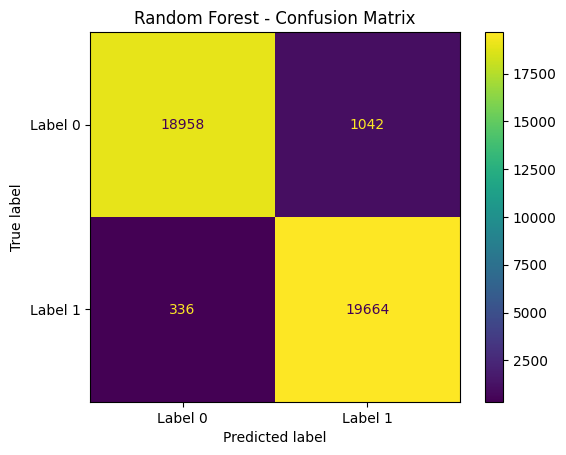

Confusion matrix:
[[18958  1042]
 [  336 19664]]


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Label 0", "Label 1"]
)

display_matrix.plot(values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.show()

print("Confusion matrix:")
print(cm)

In [23]:
# Inspect examples for each label
for label in sorted(df["Label"].unique()):
    print(f"\nLabel {label} — sample URLs")
    display(
        df.loc[df["Label"] == label, ["URL", "Label"]]
          .sample(n=min(10, (df["Label"] == label).sum()), random_state=42)
    )


Label 0 — sample URLs


,URL,Label
151353,https://www.mesharepoint.com/eur/631f985f-427e...,0
160334,https://facilitaire-controle.tk/index.php/fals...,0
39690,https://bafybeigyp2cjhkqpljyz5cjeu6elqhbljivyh...,0
153306,https://openseas.firebaseapp.com,0
185952,https://storageapi.fleek.co/ed7a9bea-5e3d-4850...,0
152822,https://mail.alertasegurosimtebankpe-ingresape...,0
167934,http://svdcq.blogspot.ug,0
161806,https://162.241.69.15/982a4914b2406e478658e6ad...,0
121327,http://paypal.aisgwb.org/02a42d754be2a43c77700...,0
99853,https://www.securmaccu.ftpserver.biz/cgi/ICCU/...,0



Label 1 — sample URLs


,URL,Label
151518,https://www.mtt.gov.rs,1
160409,https://www.12stepapps.org,1
39772,https://www.ou.nl,1
153489,https://www.kataweb.it,1
186024,https://www.toool.us,1
152935,https://www.igumbi.com,1
168099,https://www.exceptionalappstudios.com,1
161872,https://www.northcarolinafc.com,1
121729,https://www.gamma.umd.edu,1
100410,https://www.fmo.nl,1


In [24]:
def predict_url(url):
    features = pd.DataFrame([extract_features(url)])
    prediction = int(model.predict(features)[0])

    print("URL:", url)

    if prediction == 0:
        print("Prediction: LIKELY PHISHING")
    else:
        print("Prediction: LIKELY LEGITIMATE")

    print("\nNote: This is an ML prediction, not a security guarantee.")

# Test examples
predict_url("https://www.google.com")
print("\n" + "-" * 50 + "\n")
predict_url("http://paypal.aisgwb.org/02a42d754be2a43c77700")

URL: https://www.google.com
Prediction: LIKELY LEGITIMATE

Note: This is an ML prediction, not a security guarantee.

--------------------------------------------------

URL: http://paypal.aisgwb.org/02a42d754be2a43c77700
Prediction: LIKELY PHISHING

Note: This is an ML prediction, not a security guarantee.


In [25]:
def predict_url(url):
    features = pd.DataFrame([extract_features(url)])

    prediction = int(model.predict(features)[0])
    probabilities = model.predict_proba(features)[0]

    # Probability of the predicted class
    confidence = probabilities[prediction] * 100

    print("URL:", url)

    if prediction == 0:
        print("Prediction: LIKELY PHISHING")
    else:
        print("Prediction: LIKELY LEGITIMATE")

    print(f"Model confidence: {confidence:.2f}%")
    print(f"Phishing probability: {probabilities[0] * 100:.2f}%")
    print(f"Legitimate probability: {probabilities[1] * 100:.2f}%")

    print("\nNote: Probabilities are model estimates, not proof of safety.")

# Test
predict_url("https://www.google.com")

URL: https://www.google.com
Prediction: LIKELY LEGITIMATE
Model confidence: 98.62%
Phishing probability: 1.38%
Legitimate probability: 98.62%

Note: Probabilities are model estimates, not proof of safety.


In [26]:
import joblib

# Save trained model and feature names
joblib.dump(model, "phishing_url_model.pkl")
joblib.dump(list(X.columns), "phishing_url_features.pkl")

print("Model saved successfully!")
print("1. phishing_url_model.pkl")
print("2. phishing_url_features.pkl")

Model saved successfully!
1. phishing_url_model.pkl
2. phishing_url_features.pkl


In [27]:
import joblib
import pandas as pd

# Load the saved model
loaded_model = joblib.load("phishing_url_model.pkl")

# Load the feature names
loaded_features = joblib.load("phishing_url_features.pkl")

print("Saved model loaded successfully!")
print("Number of features:", len(loaded_features))
print("Feature names:", loaded_features)

Saved model loaded successfully!
Number of features: 13
Feature names: ['url_length', 'hostname_length', 'path_length', 'dot_count', 'hyphen_count', 'subdomain_count', 'has_ip', 'has_https', 'has_at_symbol', 'has_double_slash_in_path', 'digit_count', 'suspicious_word_count', 'entropy']


In [28]:
def predict_with_saved_model(url):
    # Extract features using our existing function
    features = pd.DataFrame([extract_features(url)])

    # Ensure feature order matches training
    features = features[loaded_features]

    prediction = int(loaded_model.predict(features)[0])
    probabilities = loaded_model.predict_proba(features)[0]

    result = "LIKELY PHISHING" if prediction == 0 else "LIKELY LEGITIMATE"

    print("URL:", url)
    print("Prediction:", result)
    print(f"Phishing probability: {probabilities[0] * 100:.2f}%")
    print(f"Legitimate probability: {probabilities[1] * 100:.2f}%")

predict_with_saved_model("https://www.google.com")

URL: https://www.google.com
Prediction: LIKELY LEGITIMATE
Phishing probability: 1.38%
Legitimate probability: 98.62%


In [29]:
readme_content = """
# Phishing URL Detection for Defence Personnel

## Overview
A machine learning prototype that classifies URLs as
likely phishing or likely legitimate using URL-based features.

## Problem Statement
Phishing URLs can trick users into visiting fraudulent
websites or sharing sensitive information. This project
explores automated URL classification as a defensive aid.

## Technology Stack
- Python
- Pandas and NumPy
- Scikit-learn
- Random Forest Classifier
- Google Colab
- Joblib

## Dataset
PhishURL dataset containing URLs and their labels.
The current dataset contains approximately 200,000 records
before cleaning and duplicate removal.

Label mapping used:
- 0 = Phishing
- 1 = Legitimate

## Features
The model uses 13 URL-derived features, including:
- URL length and hostname length
- Number of dots and hyphens
- Approximate subdomain count
- IP-address indicator
- HTTPS indicator
- Special-character indicators
- Digit count
- Suspicious-word count
- Character entropy

## Model
Random Forest Classifier with 100 decision trees.

## Initial Evaluation
- Accuracy: 96.56%
- Precision: 94.97%
- Recall: 98.32%
- F1-score: 96.61%

These are initial results on a random held-out test split.
They may not reflect performance on new, real-world URLs.

## Limitations
- Uses URL-derived features only.
- Does not inspect webpage content or live reputation.
- Dataset labels and potential duplicates require further validation.
- Predicted probabilities are not guarantees of safety.
- Not intended as a standalone operational defence system.

## Future Improvements
- Validate labels and data quality.
- Test on an independent, newer dataset.
- Check for duplicate and domain-level data leakage.
- Evaluate false negatives and false positives.
- Explore integration with trusted threat-intelligence sources.

## Disclaimer
This is an educational defensive cybersecurity prototype.
Do not rely on it alone to decide whether a URL is safe.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip())

print("README.md created successfully!")

README.md created successfully!


In [30]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
from urllib.parse import urlparse

def get_hostname(url):
    url = str(url).strip()
    parsed = urlparse(url if "://" in url else "http://" + url)
    return (parsed.hostname or "").lower()

train_hosts = set(df.loc[X_train.index, "URL"].apply(get_hostname))
test_hosts = set(df.loc[X_test.index, "URL"].apply(get_hostname))

common_hosts = train_hosts.intersection(test_hosts)

print("Unique hostnames in training:", len(train_hosts))
print("Unique hostnames in testing:", len(test_hosts))
print("Hostnames present in both:", len(common_hosts))

if len(test_hosts) > 0:
    print(
        "Test hostnames also seen in training:",
        f"{len(common_hosts) / len(test_hosts) * 100:.2f}%"
    )

print("\nExamples of overlapping hostnames:")
print(list(sorted(common_hosts))[:10])

Unique hostnames in training: 144049
Unique hostnames in testing: 37424
Hostnames present in both: 2930
Test hostnames also seen in training: 7.83%

Examples of overlapping hostnames:
['000ogxd.wcomhost.com', '044ac74.wcomhost.com', '04888e6.netsolhost.com', '0552af2.wcomhost.com', '0562ce6.wcomhost.com', '0583z.mjt.lu', '0ad8b925.ithemeshosting.com.php73-39.lan3-1.websitetestlink.com', '0ed874b.wcomhost.com', '0edc1d1.wcomhost.com', '0efbd9f.wcomhost.com']


In [32]:
from sklearn.metrics import accuracy_score, classification_report

# Identify test rows whose hostname never appeared in training
test_hosts_per_row = df.loc[X_test.index, "URL"].apply(get_hostname)

unseen_mask = ~test_hosts_per_row.isin(train_hosts)

X_unseen = X_test.loc[unseen_mask]
y_unseen = y_test.loc[unseen_mask]

print("Unseen-hostname test URLs:", len(X_unseen))

if len(X_unseen) > 0:
    unseen_pred = model.predict(X_unseen)

    print(
        "\nUnseen-hostname accuracy:",
        f"{accuracy_score(y_unseen, unseen_pred) * 100:.2f}%"
    )

    print("\nClassification report:")
    print(classification_report(
        y_unseen,
        unseen_pred,
        target_names=["Phishing (0)", "Legitimate (1)"],
        zero_division=0
    ))
else:
    print("No unseen-hostname test URLs found.")

Unseen-hostname test URLs: 34681

Unseen-hostname accuracy: 96.08%

Classification report:
                precision    recall  f1-score   support

  Phishing (0)       0.98      0.93      0.95     14682
Legitimate (1)       0.95      0.98      0.97     19999

      accuracy                           0.96     34681
     macro avg       0.96      0.96      0.96     34681
  weighted avg       0.96      0.96      0.96     34681



In [33]:

# Find phishing URLs incorrectly predicted as legitimate
false_negatives = X_unseen[
    (y_unseen == 0) & (unseen_pred == 1)
].copy()

false_negative_urls = df.loc[
    false_negatives.index, ["URL", "Label"]
].copy()

print("Phishing URLs missed by the model:", len(false_negative_urls))
display(false_negative_urls.head(20))

Phishing URLs missed by the model: 1022


,URL,Label
8162,https://wk4.mmzhoukan.com,0
115136,https://www.smqzkf.cyou,0
199702,https://www.northcotechiropractic.com,0
193758,https://bou.nxz.temporary.site,0
18413,https://wbdxa.blogspot.is,0
67463,https://www.chattgroupwhatsapp.wwwonlineind.ga,0
132156,https://blookfi.godaddysites.com,0
41534,https://www.3656nuld.xyz,0
15839,https://aeon.co.jp.miky.top,0
121435,https://authsecuritecle.web.app,0


In [34]:
# Extract features for the missed URLs
fn_features = pd.DataFrame(
    false_negative_urls["URL"].apply(extract_features).tolist(),
    index=false_negative_urls.index
)

print("False negatives:", len(fn_features))

print("\nAverage features of missed phishing URLs:")
display(fn_features.mean().round(2).to_frame("Average"))

print("\nCompare with correctly detected phishing URLs:")
correct_phishing_idx = X_unseen.index[
    (y_unseen == 0) & (unseen_pred == 0)
]

correct_phishing_features = X.loc[correct_phishing_idx]

comparison = pd.DataFrame({
    "Missed phishing": fn_features.mean(),
    "Correctly detected phishing": correct_phishing_features.mean()
})

display(comparison.round(2))

False negatives: 1022

Average features of missed phishing URLs:


,Average
url_length,30.76
hostname_length,22.76
path_length,0.00
dot_count,2.17
hyphen_count,0.27
subdomain_count,1.17
has_ip,0.00
has_https,1.00
has_at_symbol,0.00
has_double_slash_in_path,0.00



Compare with correctly detected phishing URLs:


,Missed phishing,Correctly detected phishing
url_length,30.76,62.43
hostname_length,22.76,25.63
path_length,0.00,17.13
dot_count,2.17,2.44
hyphen_count,0.27,1.01
subdomain_count,1.17,0.90
has_ip,0.00,0.01
has_https,1.00,0.60
has_at_symbol,0.00,0.02
has_double_slash_in_path,0.00,0.00


,Feature,Importance
2,path_length,0.239638
0,url_length,0.195637
10,digit_count,0.125495
12,entropy,0.114493
7,has_https,0.108004
5,subdomain_count,0.086515
4,hyphen_count,0.057187
3,dot_count,0.036503
1,hostname_length,0.024625
11,suspicious_word_count,0.011056


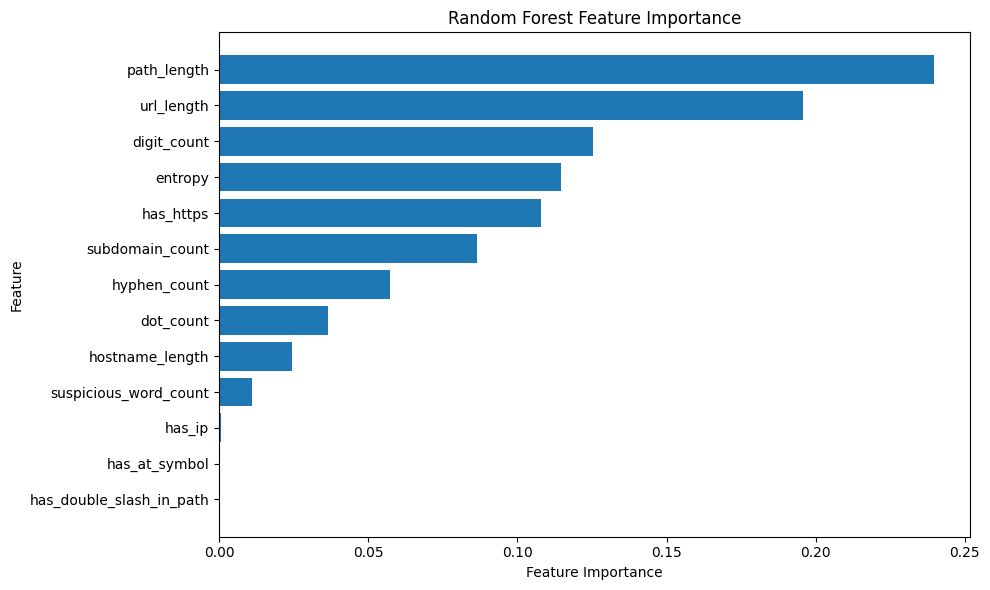

In [35]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [36]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Har URL ka hostname nikalo
groups = df.loc[X.index, "URL"].apply(get_hostname)

# Same hostname ko train aur test dono mein jaane se roko
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_test_group = X.iloc[test_idx]

y_train_group = y.iloc[train_idx]
y_test_group = y.iloc[test_idx]

# Naya model train karo
group_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

group_model.fit(X_train_group, y_train_group)

# Test set par predictions
group_pred = group_model.predict(X_test_group)

print("Training rows:", len(X_train_group))
print("Testing rows:", len(X_test_group))

print(
    "\nHostname overlap:",
    len(set(groups.iloc[train_idx]) &
        set(groups.iloc[test_idx]))
)

print("\nAccuracy:",
      round(accuracy_score(y_test_group, group_pred) * 100, 2),
      "%")

print("\nClassification Report:")
print(classification_report(
    y_test_group,
    group_pred,
    labels=[0, 1],
    target_names=["Phishing (0)", "Legitimate (1)"],
    zero_division=0
))

Training rows: 160648
Testing rows: 39352

Hostname overlap: 0

Accuracy: 96.36 %

Classification Report:
                precision    recall  f1-score   support

  Phishing (0)       0.98      0.94      0.96     19351
Legitimate (1)       0.95      0.98      0.96     20001

      accuracy                           0.96     39352
     macro avg       0.96      0.96      0.96     39352
  weighted avg       0.96      0.96      0.96     39352



Confusion Matrix:
[[18262  1089]
 [  345 19656]]


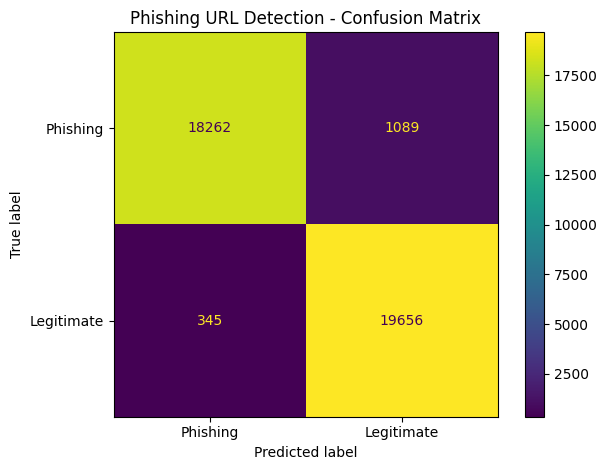

Correctly detected phishing: 18262
Phishing missed as legitimate: 1089
Legitimate flagged as phishing: 345
Correctly identified legitimate: 19656


In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_group,
    group_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

display_labels = ["Phishing", "Legitimate"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("Phishing URL Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("Correctly detected phishing:", tn)
print("Phishing missed as legitimate:", fp)
print("Legitimate flagged as phishing:", fn)
print("Correctly identified legitimate:", tp)

In [39]:
# Actual phishing (0), but predicted legitimate (1)
missed_mask = (y_test_group == 0) & (group_pred == 1)

missed_indices = y_test_group.index[missed_mask]

missed_urls = df.loc[missed_indices, ["URL", "Label"]].copy()

print("Total missed phishing URLs:", len(missed_urls))

display(missed_urls.head(20))

Total missed phishing URLs: 1089


,URL,Label
44,https://www.officialcompanypdf.pro,0
56,https://hg7y.ktt55.my.id,0
199,https://ufjapan.penjingw.cn,0
254,https://ff.member.garenaa.io.vn,0
653,https://www-amozon.blogcard.shop,0
1196,https://abpijwutyd.duckdns.org,0
1861,https://grub-whatsapp.vixxp.cf,0
1968,https://jklnhzpcny.duckdns.org,0
2057,https://www.amaliomano.com,0
2518,https://qvfxw.blogspot.sn,0


In [40]:
# Correctly detected phishing URLs
correct_mask = (y_test_group == 0) & (group_pred == 0)
correct_indices = y_test_group.index[correct_mask]

# Feature comparison
missed_features = X.loc[missed_indices]
correct_features = X.loc[correct_indices]

comparison = pd.DataFrame({
    "Missed phishing": missed_features.mean(),
    "Correctly detected phishing": correct_features.mean()
})

comparison["Difference"] = (
    comparison["Missed phishing"]
    - comparison["Correctly detected phishing"]
)

display(
    comparison.sort_values(
        by="Difference",
        key=abs,
        ascending=False
    ).round(3)
)

,Missed phishing,Correctly detected phishing,Difference
url_length,30.781,75.291,-44.510
path_length,0.000,26.162,-26.162
digit_count,0.202,10.988,-10.786
hostname_length,22.781,25.123,-2.342
hyphen_count,0.299,1.203,-0.904
entropy,3.958,4.380,-0.422
has_https,1.000,0.611,0.389
dot_count,2.174,2.509,-0.335
subdomain_count,1.174,0.892,0.282
suspicious_word_count,0.010,0.249,-0.239


In [41]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report

extra_model = ExtraTreesClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Same hostname-separated split
extra_model.fit(X_train_group, y_train_group)

extra_pred = extra_model.predict(X_test_group)

print("Extra Trees Accuracy:",
      round(accuracy_score(y_test_group, extra_pred) * 100, 2),
      "%")

print("\nClassification Report:")
print(classification_report(
    y_test_group,
    extra_pred,
    labels=[0, 1],
    target_names=["Phishing (0)", "Legitimate (1)"],
    zero_division=0
))

Extra Trees Accuracy: 96.39 %

Classification Report:
                precision    recall  f1-score   support

  Phishing (0)       0.98      0.94      0.96     19351
Legitimate (1)       0.95      0.98      0.97     20001

      accuracy                           0.96     39352
     macro avg       0.97      0.96      0.96     39352
  weighted avg       0.96      0.96      0.96     39352



In [42]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Labels order: 0 = Phishing, 1 = Legitimate
rf_cm = confusion_matrix(
    y_test_group, group_pred, labels=[0, 1]
)

et_cm = confusion_matrix(
    y_test_group, extra_pred, labels=[0, 1]
)

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Phishing missed as legitimate",
        "Legitimate flagged as phishing",
        "Phishing recall (%)"
    ],
    "Random Forest": [
        round(accuracy_score(y_test_group, group_pred) * 100, 2),
        int(rf_cm[0, 1]),
        int(rf_cm[1, 0]),
        round(rf_cm[0, 0] / (rf_cm[0, 0] + rf_cm[0, 1]) * 100, 2)
    ],
    "Extra Trees": [
        round(accuracy_score(y_test_group, extra_pred) * 100, 2),
        int(et_cm[0, 1]),
        int(et_cm[1, 0]),
        round(et_cm[0, 0] / (et_cm[0, 0] + et_cm[0, 1]) * 100, 2)
    ]
})

display(comparison_df)

,Metric,Random Forest,Extra Trees
0,Accuracy (%),96.36,96.39
1,Phishing missed as legitimate,1089.00,1113.00
2,Legitimate flagged as phishing,345.00,306.00
3,Phishing recall (%),94.37,94.25


In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score

rf_sensitive = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1,
    class_weight={0: 2, 1: 1}
)

rf_sensitive.fit(X_train_group, y_train_group)

sensitive_pred = rf_sensitive.predict(X_test_group)

cm_sensitive = confusion_matrix(
    y_test_group,
    sensitive_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_sensitive.ravel()

print("Accuracy:",
      round(accuracy_score(y_test_group, sensitive_pred) * 100, 2), "%")

print("Phishing recall:",
      round(tn / (tn + fp) * 100, 2), "%")

print("Phishing missed:", fp)
print("Legitimate flagged as phishing:", fn)

print("\nClassification Report:")
print(classification_report(
    y_test_group,
    sensitive_pred,
    labels=[0, 1],
    target_names=["Phishing (0)", "Legitimate (1)"],
    zero_division=0
))

Accuracy: 96.16 %
Phishing recall: 94.66 %
Phishing missed: 1033
Legitimate flagged as phishing: 478

Classification Report:
                precision    recall  f1-score   support

  Phishing (0)       0.97      0.95      0.96     19351
Legitimate (1)       0.95      0.98      0.96     20001

      accuracy                           0.96     39352
     macro avg       0.96      0.96      0.96     39352
  weighted avg       0.96      0.96      0.96     39352



In [44]:
import joblib

# Candidate model save karo
joblib.dump(rf_sensitive, "phishing_url_model.pkl")

# Feature order bhi save karo
joblib.dump(list(X.columns), "phishing_url_features.pkl")

print("Candidate model saved successfully!")
print("Model: phishing_url_model.pkl")
print("Features: phishing_url_features.pkl")

Candidate model saved successfully!
Model: phishing_url_model.pkl
Features: phishing_url_features.pkl


In [45]:

fn_features = X_unseen.loc[false_negatives.index]

correct_phishing = X_unseen[
    (y_unseen == 0) & (unseen_pred == 0)
]

comparison = pd.DataFrame({
    "Missed phishing": fn_features.mean(),
    "Correctly detected phishing":
        X_unseen.loc[correct_phishing.index].mean()
})

comparison["Difference"] = (
    comparison["Missed phishing"]
    - comparison["Correctly detected phishing"]
)

display(comparison.sort_values("Difference", ascending=False))


,Missed phishing,Correctly detected phishing,Difference
has_https,1.000000,0.596633,0.403367
subdomain_count,1.170254,0.896266,0.273988
has_double_slash_in_path,0.000000,0.000512,-0.000512
has_ip,0.000000,0.010469,-0.010469
has_at_symbol,0.000000,0.020571,-0.020571
suspicious_word_count,0.002935,0.224524,-0.221589
dot_count,2.170254,2.442753,-0.272498
entropy,3.959233,4.296946,-0.337713
hyphen_count,0.274951,1.014641,-0.739690
hostname_length,22.759295,25.630527,-2.871232


,Feature,Importance
2,path_length,0.239638
0,url_length,0.195637
10,digit_count,0.125495
12,entropy,0.114493
7,has_https,0.108004
5,subdomain_count,0.086515
4,hyphen_count,0.057187
3,dot_count,0.036503
1,hostname_length,0.024625
11,suspicious_word_count,0.011056


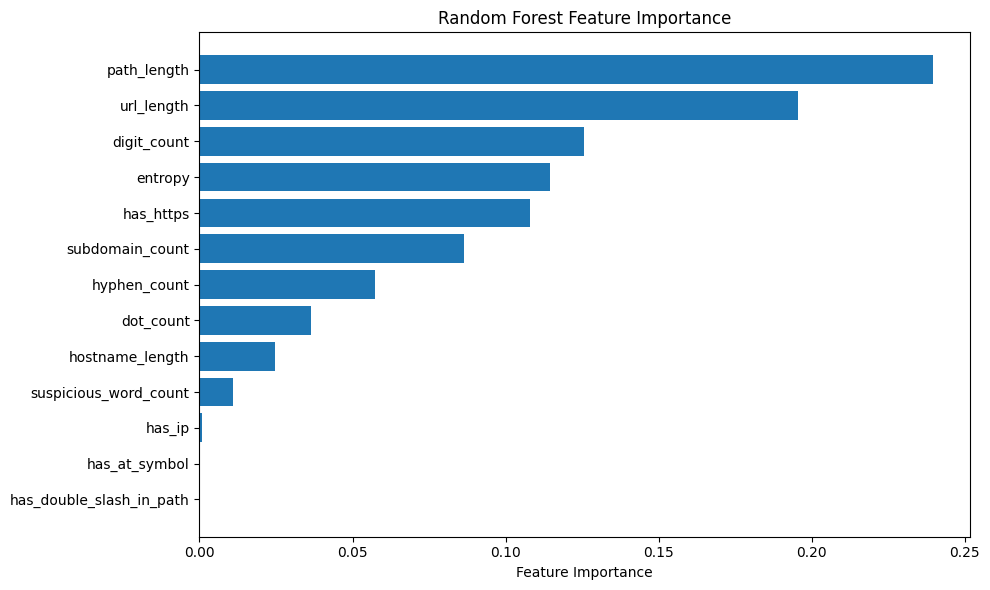

In [46]:

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


In [47]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )
}

results = []

for name, clf in models.items():
    print(f"Training {name}...")

    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test, pred, zero_division=0) * 100, 2
        ),
        "Recall - Phishing (%)": round(
            recall_score(y_test, pred, pos_label=0, zero_division=0) * 100, 2
        ),
        "F1 - Phishing (%)": round(
            f1_score(y_test, pred, pos_label=0, zero_division=0) * 100, 2
        )
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("F1 - Phishing (%)", ascending=False))


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


,Model,Accuracy (%),Precision (%),Recall - Phishing (%),F1 - Phishing (%)
2,Random Forest,96.56,94.97,94.79,96.49
1,Decision Tree,96.27,94.90,94.74,96.21
0,Logistic Regression,95.14,92.22,91.68,94.96


In [48]:

import joblib
import json

# Save the Random Forest candidate
final_model = models["Random Forest"]

joblib.dump(final_model, "phishing_url_model.pkl")
joblib.dump(list(X.columns), "phishing_url_features.pkl")

# Save evaluation metrics
final_metrics = {
    "model": "Random Forest",
    "accuracy_percent": 96.56,
    "precision_label_1_percent": 94.97,
    "recall_phishing_label_0_percent": 94.79,
    "f1_phishing_label_0_percent": 96.49,
    "dataset": "PhishURL",
    "number_of_features": len(X.columns)
}

with open("model_metrics.json", "w") as file:
    json.dump(final_metrics, file, indent=4)

print("Candidate model saved!")
print("- phishing_url_model.pkl")
print("- phishing_url_features.pkl")
print("- model_metrics.json")


Candidate model saved!
- phishing_url_model.pkl
- phishing_url_features.pkl
- model_metrics.json


In [49]:

from google.colab import files

files.download("phishing_url_model.pkl")
files.download("phishing_url_features.pkl")
files.download("model_metrics.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>